<h2 style="color:blue" align="center">Handwritten digits classification using neural network</h2>

In this notebook we will classify handwritten digits using a simple neural network which has only input and output layers. We will than add a hidden layer and see how the performance of the model improves

In [1]:
!pip install tensorflow

zsh:1: command not found: pip


In [2]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
# %matplotlib inline
import numpy as np

In [3]:
(X_train, y_train) , (X_test, y_test) = keras.datasets.mnist.load_data()

In [4]:
len(X_train)

60000

In [5]:
len(X_test)

10000

In [6]:
X_train[0].shape

(28, 28)

In [7]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

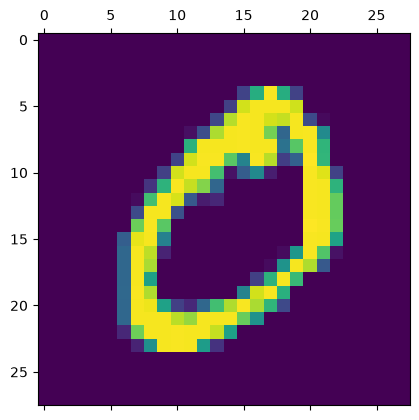

In [8]:
plt.matshow(X_train[1])
plt.show()

In [9]:
y_train[1]

np.uint8(0)

In [10]:
#Scaling
X_train = X_train / 255
X_test = X_test / 255

In [11]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [12]:
X_train_flattened = X_train.reshape(len(X_train), 28*28)
X_test_flattened = X_test.reshape(len(X_test), 28*28)

In [13]:
X_train_flattened.shape
#X_test_flattened.shape

(60000, 784)

In [14]:
X_train_flattened[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

<h3 style='color:purple'>Very simple neural network with no hidden layers</h3>

In [15]:
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,), activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train_flattened, y_train, epochs=5)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 5:29 176ms/step - accuracy: 0.1250 - loss: 2.3290

 169/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 298us/step - accuracy: 0.7310 - loss: 1.1371  

 347/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 290us/step - accuracy: 0.7975 - loss: 0.8541

 519/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 290us/step - accuracy: 0.8230 - loss: 0.7273

... (61 outputs left out)

1378/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 291us/step - accuracy: 0.9248 - loss: 0.2702

1556/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 290us/step - accuracy: 0.9251 - loss: 0.2688

1729/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 290us/step - accuracy: 0.9255 - loss: 0.2681

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 294us/step - accuracy: 0.9256 - loss: 0.2668


In [16]:
model.evaluate(X_test_flattened, y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9688 - loss: 0.2711

188/313 ━━━━━━━━━━━━━━━━━━━━ 0s 269us/step - accuracy: 0.9136 - loss: 0.3144

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 284us/step - accuracy: 0.9261 - loss: 0.2687


[0.26874473690986633, 0.9261000156402588]

In [17]:
y_predicted = model.predict(X_test_flattened)
y_predicted[0]

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step

271/313 ━━━━━━━━━━━━━━━━━━━━ 0s 186us/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 221us/step


array([2.47991085e-02, 4.59155302e-07, 3.83128934e-02, 9.56285000e-01,
       2.75544100e-03, 1.35375008e-01, 1.24353585e-06, 9.99857545e-01,
       1.09579764e-01, 6.49854302e-01], dtype=float32)

In [18]:
y_test[0]

np.uint8(7)

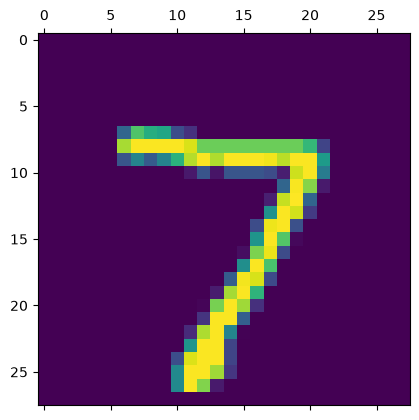

In [19]:
plt.matshow(X_test[0])
plt.show()

**np.argmax finds a maximum element  from an array and returns the index of it**

In [20]:
np.argmax(y_predicted[0])

np.int64(7)

In [21]:
y_predicted_labels = [np.argmax(i) for i in y_predicted]

In [22]:
y_predicted_labels[:5]

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4)]

In [23]:
cm = tf.math.confusion_matrix(labels=y_test,predictions=y_predicted_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 961,    0,    0,    2,    0,    6,    5,    3,    3,    0],
       [   0, 1115,    3,    2,    0,    1,    4,    2,    8,    0],
       [   7,   10,  906,   17,    7,    5,   13,   12,   53,    2],
       [   4,    0,   14,  913,    0,   27,    3,   13,   29,    7],
       [   1,    1,    3,    1,  914,    0,   11,    5,   10,   36],
       [   8,    3,    1,   27,    6,  783,   14,    7,   36,    7],
       [  11,    3,    5,    1,    7,   14,  912,    2,    3,    0],
       [   1,    6,   20,    5,    6,    0,    0,  963,    4,   23],
       [   5,    9,    5,   16,    9,   22,    9,   12,  881,    6],
       [   9,    7,    2,    9,   24,    8,    0,   27,   10,  913]],
      dtype=int32)>

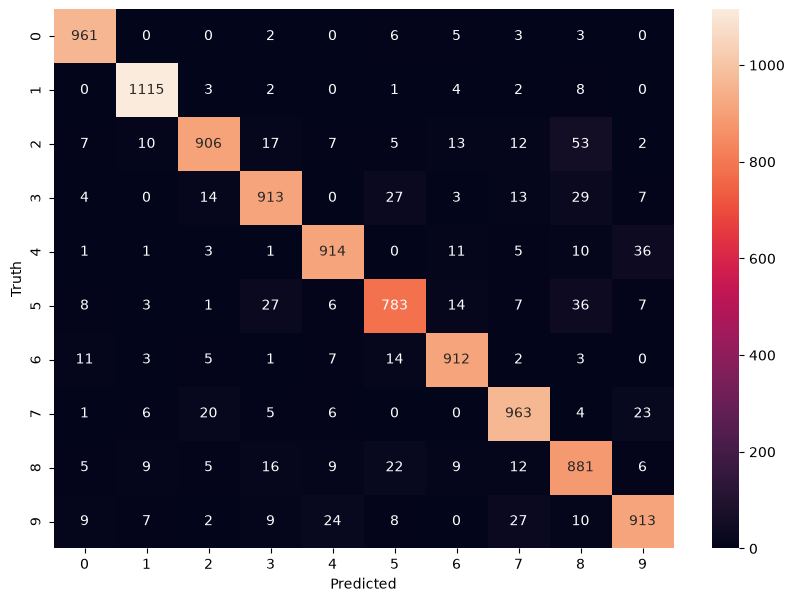

In [24]:
import seaborn as sn
plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

<h3 style='color:purple'>Using hidden layer</h3>

In [25]:
model = keras.Sequential([
    keras.layers.Dense(100, input_shape=(784,), activation='relu'),
    
    keras.layers.Dense(10, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train_flattened, y_train, epochs=5)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 6:29 208ms/step - accuracy: 0.1250 - loss: 2.2460

  86/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 593us/step - accuracy: 0.7366 - loss: 0.9928  

 171/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 614us/step - accuracy: 0.8099 - loss: 0.7155

 244/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 637us/step - accuracy: 0.8354 - loss: 0.6106

... (99 outputs left out)

1617/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step - accuracy: 0.9842 - loss: 0.0513

1719/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step - accuracy: 0.9843 - loss: 0.0513

1820/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step - accuracy: 0.9840 - loss: 0.0519

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 500us/step - accuracy: 0.9840 - loss: 0.0518


In [26]:
model.evaluate(X_test_flattened,y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9688 - loss: 0.0409

164/313 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step - accuracy: 0.9667 - loss: 0.1083

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step - accuracy: 0.9745 - loss: 0.0842


[0.08420044183731079, 0.9745000004768372]

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step

215/313 ━━━━━━━━━━━━━━━━━━━━ 0s 234us/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 258us/step


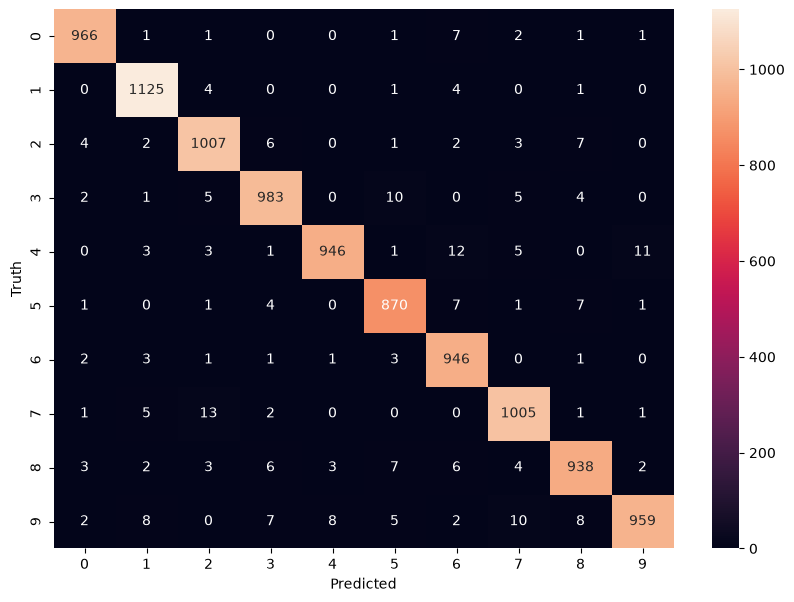

In [27]:
y_predicted = model.predict(X_test_flattened)
y_predicted_labels = [np.argmax(i) for i in y_predicted]
cm = tf.math.confusion_matrix(labels=y_test,predictions=y_predicted_labels)

plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

<h3 style='color:purple'>Using Flatten layer so that we don't have to call .reshape on input dataset</h3>

In [28]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=10)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10


   1/1875 ━━━━━━━━━━━━━━━━━━━━ 6:59 224ms/step - accuracy: 0.0625 - loss: 2.4169

  90/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 568us/step - accuracy: 0.7392 - loss: 0.9590  

 179/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 567us/step - accuracy: 0.8080 - loss: 0.7011

 269/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 565us/step - accuracy: 0.8370 - loss: 0.5882

... (210 outputs left out)

1612/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 530us/step - accuracy: 0.9948 - loss: 0.0172

1711/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 529us/step - accuracy: 0.9946 - loss: 0.0178

1810/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 528us/step - accuracy: 0.9944 - loss: 0.0180

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 530us/step - accuracy: 0.9943 - loss: 0.0183


In [29]:
model.evaluate(X_test,y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 1.0000 - loss: 0.0211

160/313 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step - accuracy: 0.9668 - loss: 0.1266

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step - accuracy: 0.9761 - loss: 0.0925


[0.09249536693096161, 0.9761000275611877]